# Mall customer segmentation
How do three clustering methods group shoppers using annual income and spending score? This notebook generates 300 synthetic mall customers, chooses a cluster count for each method, and compares their assignments. The generator includes an elongated middle group so cluster shape matters.

Run the cells from top to bottom in a Python 3 Jupyter notebook with NumPy, pandas, Matplotlib, SciPy, and scikit-learn installed. The dataset is generated in memory with a fixed seed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
FEATURES = ["Annual income ($k)", "Spending score"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlelocation": "left", "font.size": 10})

## Generate the customers
Annual income is measured in thousands of dollars. Spending score is a synthetic index from 1 to 100, with higher values indicating more spending. Each simulated group has a different center, spread, and income–score correlation. The rows are shuffled so customer IDs carry no information about group membership.

In [2]:
# Each row gives group size, feature means, standard deviations, and correlation.
populations = [
    (55, (34, 22), (8, 7),   0.35),
    (48, (32, 78), (7, 9),  -0.30),
    (90, (65, 50), (14, 7),  0.82),
    (47, (96, 22), (11, 9), -0.62),
    (60, (96, 78), (9, 8),   0.50),
]
rng = np.random.default_rng(SEED)
samples, source_group = [], []
for group, (size, mean, (sx, sy), corr) in enumerate(populations):
    covariance = [[sx**2, corr*sx*sy], [corr*sx*sy, sy**2]]
    samples.append(rng.multivariate_normal(mean, covariance, size))
    source_group.extend([group] * size)

values = np.vstack(samples)
values[:, 0] = np.round(np.maximum(values[:, 0], 1), 1)
values[:, 1] = np.clip(np.rint(values[:, 1]), 1, 100)
order = rng.permutation(len(values))
customers = pd.DataFrame(values[order], columns=FEATURES)
customers["Spending score"] = customers["Spending score"].astype(int)
customers.index = pd.RangeIndex(1, len(customers) + 1, name="Customer ID")
simulated_group = np.array(source_group)[order]  # Used only for final evaluation.
display(customers.head())

,Annual income ($k),Spending score
Customer ID,,
1,40.5,21
2,38.8,85
3,68.9,46
4,67.4,47
5,18.8,94


## Select the number of segments
Standardize both features to give them equal variance. Fit each method for two through eight segments using the same input rows.

| Method | How it assigns customers | How the segment count is selected |
|---|---|---|
| K-Means | Assigns each customer to the nearest centroid and minimizes within-cluster squared distances. | Highest mean silhouette |
| Agglomerative clustering (Ward) | Starts with one cluster per customer and repeatedly merges the pair that causes the smallest increase in within-cluster variance. | Highest mean silhouette |
| Gaussian mixture model (GMM) | Fits a weighted mixture of Gaussians. Each component has its own covariance and yields a membership probability for each customer. | Lowest Bayesian information criterion (BIC) |

Silhouette measures how close each customer is to their own cluster relative to the nearest other cluster. BIC balances the mixture's fit against its parameter count. The synthetic group labels are held aside during fitting and model selection.

In [3]:
X = StandardScaler().fit_transform(customers[FEATURES])
methods = ["K-Means", "Agglomerative", "GMM"]
fits, assignments, records = {}, {}, []

with threadpool_limits(limits=1):
    for k in range(2, 9):
        models = {
            "K-Means": KMeans(n_clusters=k, n_init=20, random_state=SEED),
            "Agglomerative": AgglomerativeClustering(n_clusters=k, linkage="ward"),
            "GMM": GaussianMixture(n_components=k, covariance_type="full",
                                   n_init=10, random_state=SEED),
        }
        for name, model in models.items():
            labels = model.fit_predict(X)
            fits[name, k] = model
            assignments[name, k] = labels
            records.append({
                "Method": name, "k": k, "Silhouette": silhouette_score(X, labels),
                "BIC": model.bic(X) if name == "GMM" else np.nan,
            })

scores = pd.DataFrame(records)
selected = {}
for name in methods:
    candidates = scores[scores["Method"] == name]
    best = candidates["BIC"].idxmin() if name == "GMM" else candidates["Silhouette"].idxmax()
    selected[name] = int(scores.loc[best, "k"])

grid = scores.pivot(index="k", columns="Method", values="Silhouette")[methods]
grid.columns = [f"{name} silhouette" for name in grid.columns]
grid["GMM BIC"] = scores[scores["Method"] == "GMM"].set_index("k")["BIC"]
display(grid.round(3))

,K-Means silhouette,Agglomerative silhouette,GMM silhouette,GMM BIC
k,,,,
2,0.392,0.379,0.182,1391.314
3,0.455,0.458,0.362,1299.726
4,0.564,0.558,0.510,1275.680
5,0.618,0.608,0.597,1228.326
6,0.560,0.532,0.549,1253.421
7,0.512,0.491,0.489,1280.159
8,0.488,0.466,0.405,1309.438


## Compare the fitted segments
The adjusted Rand index (ARI) compares pairs of customers. It equals 1 when every pair is grouped consistently with the simulation and is near 0 for chance-level agreement. It is unaffected by the numbers each algorithm uses as labels.

In [4]:
comparison = []
for name in methods:
    k = selected[name]
    labels = assignments[name, k]
    comparison.append({
        "Method": name, "Selected k": k, "Silhouette": silhouette_score(X, labels),
        "ARI vs. simulated groups": adjusted_rand_score(simulated_group, labels),
    })
display(pd.DataFrame(comparison).set_index("Method").round(3))

,Selected k,Silhouette,ARI vs. simulated groups
Method,,,
K-Means,5,0.618,0.830
Agglomerative,5,0.608,0.836
GMM,5,0.597,0.907


The panels use the original units. To make the same group recognizable across panels, the plotting code matches cluster colors by maximum overlap with GMM's assignments. This relabeling leaves the scores and fitted models unchanged.

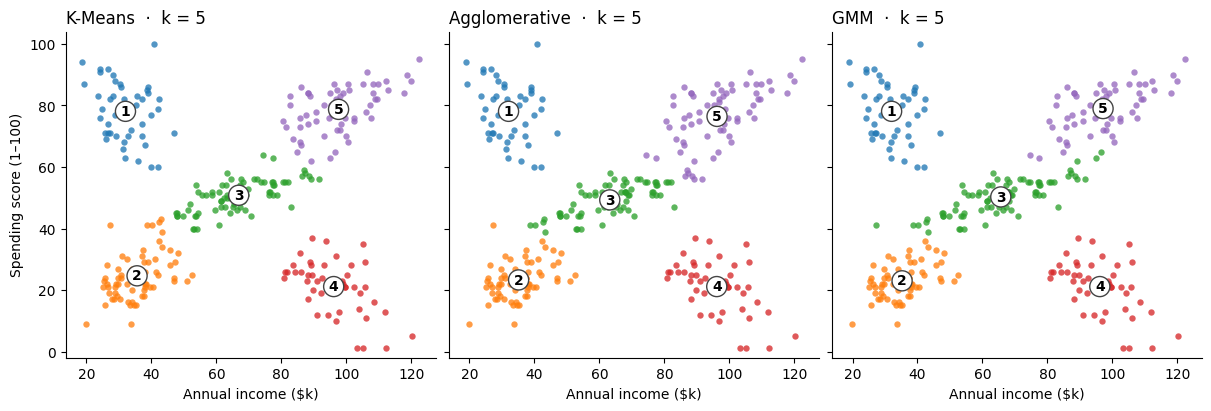

In [5]:
gmm_k = selected["GMM"]
gmm = fits["GMM", gmm_k]
gmm_labels = assignments["GMM", gmm_k]
# Sort reference segments by mean annual income, then assign IDs starting at 1.
ordered = customers.groupby(gmm_labels)[FEATURES[0]].mean().sort_values().index
gmm_ids = {label: number for number, label in enumerate(ordered, start=1)}
reference = np.array([gmm_ids[label] for label in gmm_labels])

def match_segments(labels):
    overlap = pd.crosstab(labels, reference)
    rows, cols = linear_sum_assignment(-overlap.to_numpy())
    mapping = dict(zip(overlap.index[rows], overlap.columns[cols]))
    for new_id, label in enumerate(overlap.index.difference(mapping), start=gmm_k + 1):
        mapping[label] = new_id
    return np.array([mapping[label] for label in labels])

segment_ids = {name: match_segments(assignments[name, selected[name]]) for name in methods}
colors = plt.get_cmap("tab10").colors
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True, constrained_layout=True)
for ax, name in zip(axes, methods):
    ids = segment_ids[name]
    for segment in np.unique(ids):
        group = customers.loc[ids == segment]
        ax.scatter(group[FEATURES[0]], group[FEATURES[1]], s=21, alpha=0.77,
                   color=colors[(segment - 1) % len(colors)], linewidths=0)
        center = group[FEATURES].mean()
        ax.annotate(str(segment), center, ha="center", va="center", weight="bold",
                    bbox=dict(boxstyle="circle,pad=0.22", fc="white", ec="#444444"))
    ax.set(title=f"{name}  ·  k = {selected[name]}", xlabel=FEATURES[0], ylim=(-2, 104))
axes[0].set_ylabel("Spending score (1–100)")
plt.show()

## Interpret the GMM profiles
Read mean spending score alongside mean annual income. Customers with similar income can have very different spending scores. The final column averages the probability GMM assigns to each customer's most likely segment.

In [6]:
probabilities = gmm.predict_proba(X)
results = customers.copy()
for name in methods:
    results[f"{name} segment"] = segment_ids[name]
results["GMM membership probability"] = probabilities.max(axis=1)

profiles = results.groupby("GMM segment").agg(
    Customers=("Spending score", "size"),
    **{"Mean annual income ($k)": ("Annual income ($k)", "mean"),
       "Mean spending score": ("Spending score", "mean"),
       "Mean membership probability": ("GMM membership probability", "mean")},
)
display(profiles.round({"Mean annual income ($k)": 1, "Mean spending score": 1,
                        "Mean membership probability": 3}))

,Customers,Mean annual income ($k),Mean spending score,Mean membership probability
GMM segment,,,,
1,48,32.0,78.1,1.000
2,61,35.3,23.0,0.991
3,84,65.6,50.3,0.978
4,46,96.1,21.1,1.000
5,61,97.1,79.0,0.981


### A customer near the boundary
Find the customer with the lowest maximum membership probability. The two largest probabilities show which segments are plausible under the fitted mixture.

In [ ]:
uncertain_row = probabilities.max(axis=1).argmin()
top_two = np.argsort(probabilities[uncertain_row])[-2:][::-1]
customer = customers.iloc[uncertain_row]
print(f"Customer {customer.name}: annual income ${customer.iloc[0]:.1f}k, "
      f"spending score {customer.iloc[1]:.0f}.")
for component in top_two:
    print(f"Segment {gmm_ids[component]}: {probabilities[uncertain_row, component]:.1%}")

Customer 178: annual income $96.4k, spending score 65.
Segment 3: 51.3%
Segment 5: 48.7%


## What the comparison shows
At the default seed, all three selection rules give five segments. K-Means produces the most compact, separated assignments by silhouette (0.618). GMM has the highest agreement with the simulation by ARI (0.907). Its full covariance can follow the tilted middle group visible in the plots. Ward clustering recovers a similar broad split, with some boundary customers assigned differently.

The GMM profiles separate lower-income customers into lower- and higher-spending groups and show the same split among higher-income customers. A fifth group sits near the middle of both measures. Because the generator draws from Gaussian populations, this example favors GMM's assumptions. For real mall customers the simulated labels would be unavailable, so ARI against those labels could not be computed.

In [ ]:
# Inspect customer-level assignments. Uncomment the next line to export all rows.
# results.to_csv("mall_customer_segments.csv")
display(results.head())